In [1]:
from google.colab import files
uploaded = files.upload()

Saving fashion_cnn (1).pth to fashion_cnn (1).pth


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cpu


In [3]:
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=transforms.ToTensor()
)

test_loader = DataLoader(test_data, batch_size=64, shuffle=False)
class_names = test_data.classes

print("Test images:", len(test_data))

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 309kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.59MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 19.4MB/s]

Test images: 10000


In [4]:
model = nn.Sequential(
    nn.Conv2d(1, 16, 3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(16, 32, 3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(32 * 7 * 7, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
).to(device)

weights = torch.load(
    "fashion_cnn (1).pth",
    map_location=device,
    weights_only=True
)
model.load_state_dict(weights)
model.eval()

print("Shared model loaded.")

Shared model loaded.


In [5]:
true_labels = []
predicted_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        scores = model(images.to(device))
        predictions = scores.argmax(dim=1)

        true_labels.extend(labels.tolist())
        predicted_labels.extend(predictions.cpu().tolist())

true_labels = np.array(true_labels)
predicted_labels = np.array(predicted_labels)

shirt_id = class_names.index("Shirt")
coat_id = class_names.index("Coat")

correct_indices = np.where(
    (true_labels == shirt_id) & (predicted_labels == shirt_id)
)[0]

error_indices = np.where(
    (true_labels == shirt_id) & (predicted_labels == coat_id)
)[0]

print("Correctly predicted shirts:", len(correct_indices))
print("Shirts mistaken for coats:", len(error_indices))

Correctly predicted shirts: 508
Shirts mistaken for coats: 177


In [6]:
def coat_saliency(index):
    image, _ = test_data[int(index)]
    image = image.unsqueeze(0).to(device)
    image.requires_grad_(True)

    coat_score = model(image)[0, coat_id]
    gradient = torch.autograd.grad(coat_score, image)[0]

    return gradient.abs().squeeze().detach().cpu().numpy()

print("Saliency function ready.")

Saliency function ready.


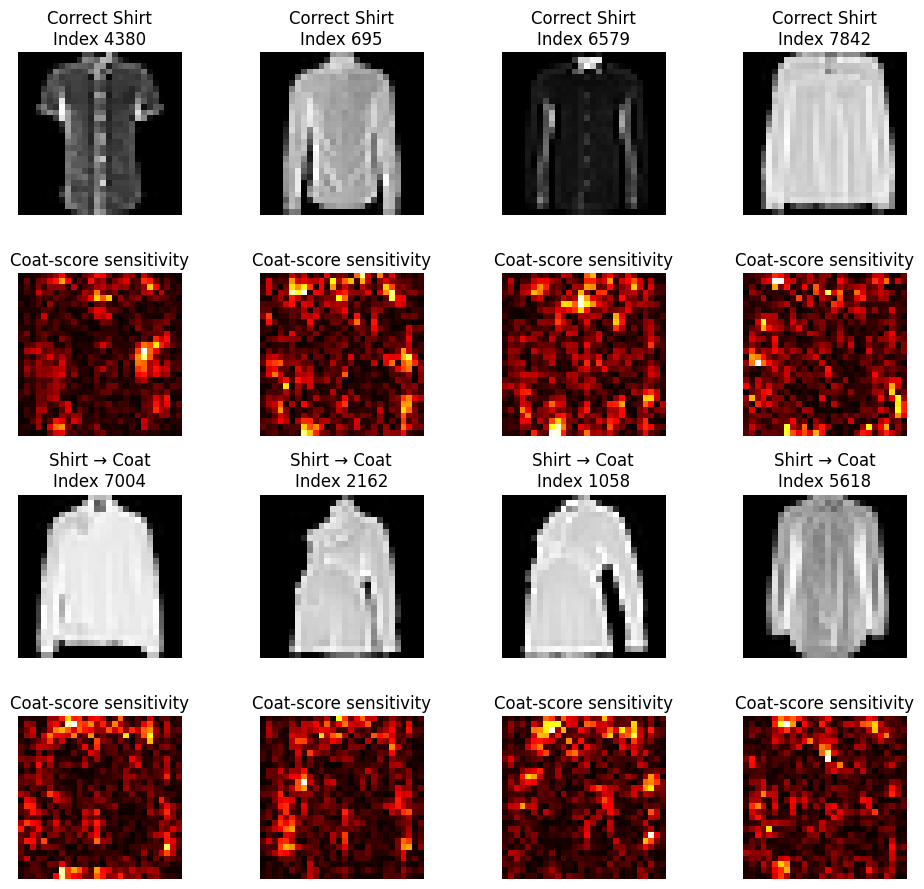

In [7]:
rng = np.random.default_rng(42)

examples = [
    ("Correct Shirt", rng.choice(correct_indices, 4, replace=False)),
    ("Shirt → Coat", rng.choice(error_indices, 4, replace=False))
]

fig, axes = plt.subplots(4, 4, figsize=(10, 9))

for group, (label, indices) in enumerate(examples):
    maps = [coat_saliency(index) for index in indices]

    for col, (index, saliency) in enumerate(zip(indices, maps)):
        image, _ = test_data[int(index)]

        axes[group * 2, col].imshow(image.squeeze(), cmap="gray")
        axes[group * 2, col].set_title(f"{label}\nIndex {index}")

        axes[group * 2 + 1, col].imshow(
            saliency / (saliency.max() + 1e-12),
            cmap="hot",
            vmin=0,
            vmax=1
        )
        axes[group * 2 + 1, col].set_title("Coat-score sensitivity")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
side_mask = np.zeros((28, 28), dtype=bool)
side_mask[15:24, 2:8] = True
side_mask[15:24, 20:26] = True

saliency_results = {}

for name, indices in [
    ("Correct Shirt", correct_indices),
    ("Shirt → Coat", error_indices)
]:
    fractions = []

    for index in indices:
        saliency = coat_saliency(index)
        fraction = saliency[side_mask].sum() / (saliency.sum() + 1e-12)
        fractions.append(fraction)

    saliency_results[name] = np.array(fractions)
    print(
        f"{name}: average lower-side sensitivity share "
        f"= {np.mean(fractions):.1%}"
    )

Correct Shirt: average lower-side sensitivity share = 18.0%
Shirt → Coat: average lower-side sensitivity share = 14.0%


We expected the lower sides to matter more when the model mistook a shirt for a coat. However, these regions accounted for 14% of the sensitivity in mistaken shirts, compared with 18% in correctly predicted shirts. This result does not support our initial idea, although it does not tell us what caused the mistakes.

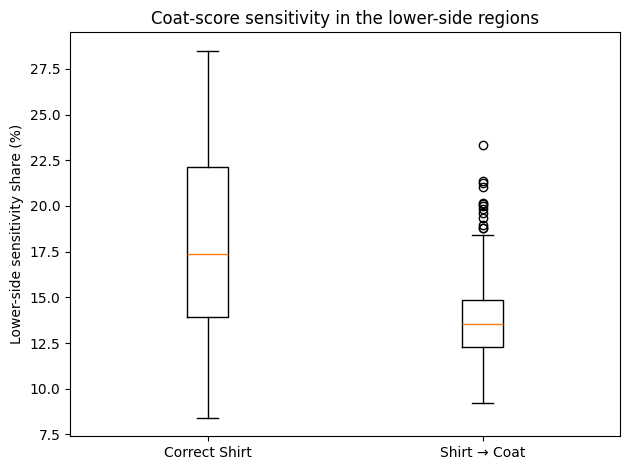

In [9]:
plt.boxplot(
    [
        saliency_results["Correct Shirt"] * 100,
        saliency_results["Shirt → Coat"] * 100
    ],
    tick_labels=["Correct Shirt", "Shirt → Coat"]
)

plt.ylabel("Lower-side sensitivity share (%)")
plt.title("Coat-score sensitivity in the lower-side regions")
plt.tight_layout()
plt.show()

We next cover the lower-side regions and check how the model’s Coat score changes. We also cover another region of the same size for comparison. This helps us investigate whether the lower sides have a particular influence on the predictions.

In [10]:
center_mask = np.zeros((28, 28), dtype=bool)
center_mask[15:24, 8:20] = True

occlusion_results = {}

for name, indices in [
    ("Correct Shirt", correct_indices),
    ("Shirt → Coat", error_indices)
]:
    images = torch.stack([
        test_data[int(index)][0] for index in indices
    ]).to(device)

    with torch.no_grad():
        original_scores = model(images)[:, coat_id]

        for region, mask in [
            ("Lower sides", side_mask),
            ("Center", center_mask)
        ]:
            covered = images.clone()
            covered[:, :, mask] = 0

            covered_scores = model(covered)[:, coat_id]
            drops = (original_scores - covered_scores).cpu().numpy()

            occlusion_results[(name, region)] = drops

            print(
                f"{name} — {region}: "
                f"average Coat-score drop = {drops.mean():.3f}"
            )

Correct Shirt — Lower sides: average Coat-score drop = 2.019
Correct Shirt — Center: average Coat-score drop = -0.486
Shirt → Coat — Lower sides: average Coat-score drop = 3.034
Shirt → Coat — Center: average Coat-score drop = 0.173


Covering the lower sides reduced the Coat score more than covering the center, especially for shirts mistaken for coats. Unlike saliency, which measures sensitivity to small changes, this test removes a whole region. The two methods give different perspectives, but blacking out pixels also changes the image unnaturally, so this does not prove what caused the mistakes.

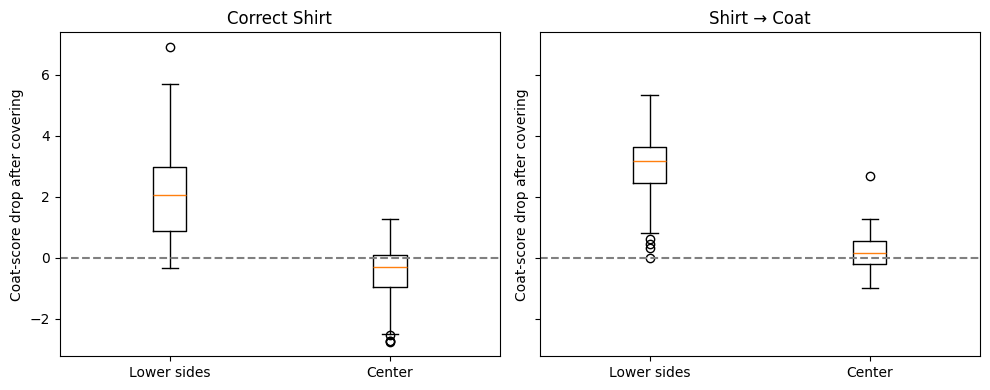

In [11]:
groups = ["Correct Shirt", "Shirt → Coat"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, name in zip(axes, groups):
    ax.boxplot(
        [
            occlusion_results[(name, "Lower sides")],
            occlusion_results[(name, "Center")]
        ],
        tick_labels=["Lower sides", "Center"]
    )
    ax.axhline(0, color="gray", linestyle="--")
    ax.set_title(name)
    ax.set_ylabel("Coat-score drop after covering")

plt.tight_layout()
plt.show()

In [12]:
error_images = torch.stack([
    test_data[int(index)][0] for index in error_indices
]).to(device)

covered_predictions = {}

with torch.no_grad():
    for region, mask in [
        ("Lower sides", side_mask),
        ("Center", center_mask)
    ]:
        covered = error_images.clone()
        covered[:, :, mask] = 0

        predictions = model(covered).argmax(dim=1).cpu().numpy()
        covered_predictions[region] = predictions

        total = len(predictions)
        shirt_count = (predictions == shirt_id).sum()
        coat_count = (predictions == coat_id).sum()
        other_count = total - shirt_count - coat_count

        print(f"\nCovering {region}:")
        print(f"Predicted Shirt: {shirt_count}/{total} ({shirt_count / total:.1%})")
        print(f"Still Coat: {coat_count}/{total} ({coat_count / total:.1%})")
        print(f"Other labels: {other_count}/{total} ({other_count / total:.1%})")


Covering Lower sides:
Predicted Shirt: 90/177 (50.8%)
Still Coat: 33/177 (18.6%)
Other labels: 54/177 (30.5%)

Covering Center:
Predicted Shirt: 7/177 (4.0%)
Still Coat: 71/177 (40.1%)
Other labels: 99/177 (55.9%)


Covering the lower sides changed the prediction from Coat to Shirt for about half of the mistaken shirts (90 out of 177). Covering the center did this for only 7 shirts. This suggests the lower-side information influences the confusion, although some predictions changed to other wrong labels. It does not prove that long sleeves caused the mistakes.

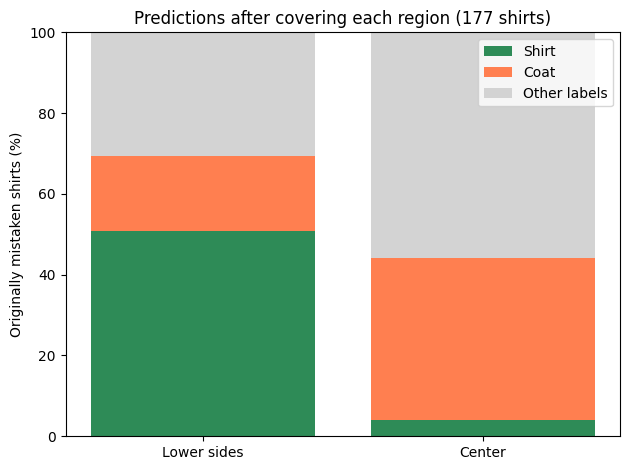

In [13]:
regions = ["Lower sides", "Center"]

shirt_rates = []
coat_rates = []
other_rates = []

for region in regions:
    predictions = covered_predictions[region]
    shirt_rates.append(100 * (predictions == shirt_id).mean())
    coat_rates.append(100 * (predictions == coat_id).mean())
    other_rates.append(
        100 * ((predictions != shirt_id) & (predictions != coat_id)).mean()
    )

plt.bar(regions, shirt_rates, label="Shirt", color="seagreen")
plt.bar(
    regions, coat_rates,
    bottom=shirt_rates, label="Coat", color="coral"
)
plt.bar(
    regions, other_rates,
    bottom=np.array(shirt_rates) + np.array(coat_rates),
    label="Other labels", color="lightgray"
)

plt.ylabel("Originally mistaken shirts (%)")
plt.title("Predictions after covering each region (177 shirts)")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
correct_images = torch.stack([
    test_data[int(index)][0] for index in correct_indices
]).to(device)

correct_covered_predictions = {}

with torch.no_grad():
    for region, mask in [
        ("Lower sides", side_mask),
        ("Center", center_mask)
    ]:
        covered = correct_images.clone()
        covered[:, :, mask] = 0

        predictions = model(covered).argmax(dim=1).cpu().numpy()
        correct_covered_predictions[region] = predictions

        total = len(predictions)
        still_correct = (predictions == shirt_id).sum()
        changed = total - still_correct

        print(f"\nCovering {region}:")
        print(
            f"Still Shirt: {still_correct}/{total} "
            f"({still_correct / total:.1%})"
        )
        print(
            f"Changed to a wrong label: {changed}/{total} "
            f"({changed / total:.1%})"
        )


Covering Lower sides:
Still Shirt: 387/508 (76.2%)
Changed to a wrong label: 121/508 (23.8%)

Covering Center:
Still Shirt: 290/508 (57.1%)
Changed to a wrong label: 218/508 (42.9%)


Covering the lower sides changed 90 of the 177 Coat mistakes to Shirt, but it also changed 121 of the 508 correct Shirt predictions to wrong labels. Covering the center disrupted even more correct predictions (42.9%). This shows that removing image regions can both help and harm predictions, so covering the lower sides is not a general solution.

So far, we have covered regions with black pixels. We next replace them with blurred pixels to check whether the result depends on how we hide the information.

In [15]:
blur_results = {}

with torch.no_grad():
    for name, images in [
        ("Correct Shirt", correct_images),
        ("Shirt → Coat", error_images)
    ]:
        blurred = transforms.functional.gaussian_blur(
            images, kernel_size=[7, 7], sigma=[2.0, 2.0]
        )
        original_scores = model(images)[:, coat_id]

        for region, mask in [
            ("Lower sides", side_mask),
            ("Center", center_mask)
        ]:
            modified = images.clone()
            modified[:, :, mask] = blurred[:, :, mask]

            scores = model(modified)
            drops = (original_scores - scores[:, coat_id]).cpu().numpy()
            predictions = scores.argmax(dim=1).cpu().numpy()

            blur_results[(name, region)] = {
                "drops": drops,
                "predictions": predictions
            }

            print(
                f"{name} — {region}: "
                f"average Coat-score drop = {drops.mean():.3f}; "
                f"predicted Shirt = {(predictions == shirt_id).mean():.1%}"
            )

Correct Shirt — Lower sides: average Coat-score drop = -0.333; predicted Shirt = 87.2%
Correct Shirt — Center: average Coat-score drop = 0.086; predicted Shirt = 89.0%
Shirt → Coat — Lower sides: average Coat-score drop = 0.268; predicted Shirt = 4.5%
Shirt → Coat — Center: average Coat-score drop = 0.158; predicted Shirt = 1.7%


Blurring the lower sides had a much smaller effect than covering them with black pixels. Only 4.5% of the mistaken shirts changed to Shirt, compared with 50.8% with black covering. Blurring preserves some information, so the two tests are different. We cannot conclude that removing fine details alone explains the earlier result.

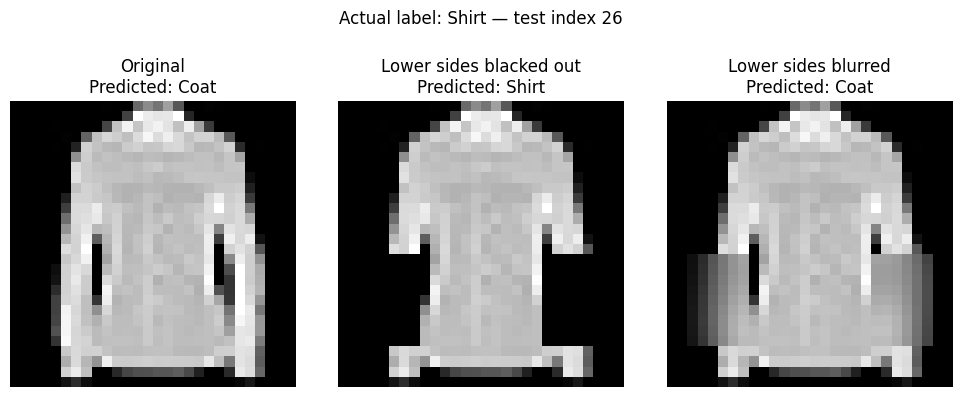

In [17]:
index = int(error_indices[0])
original, _ = test_data[index]

black = original.clone()
black[:, side_mask] = 0

blurred = transforms.functional.gaussian_blur(
    original, kernel_size=[7, 7], sigma=[2.0, 2.0]
)
softened = original.clone()
softened[:, side_mask] = blurred[:, side_mask]

versions = [original, black, softened]
titles = ["Original", "Lower sides blacked out", "Lower sides blurred"]

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

with torch.no_grad():
    for ax, image, title in zip(axes, versions, titles):
        prediction = model(image.unsqueeze(0).to(device)).argmax(dim=1).item()

        ax.imshow(image.squeeze(), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{title}\nPredicted: {class_names[prediction]}")
        ax.axis("off")

plt.suptitle(f"Actual label: Shirt — test index {index}")
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.show()

For this shirt, blacking out the lower sides changed the prediction from Coat to Shirt, while blurring them left it as Coat. Black covering removes part of the clothing shape, whereas blurring keeps much of it visible. This illustrates why the two changes may affect predictions differently, but one example cannot establish the cause.